In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv(r"C:\Users\HP\Downloads\california_housing.csv")

In [28]:
df.shape

(20640, 9)

In [16]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [17]:
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [20]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [21]:

ridge = Ridge(alpha=2.0)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

In [22]:
print("Linear Regression")
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))


Linear Regression
MSE: 0.5558915986952442
RMSE: 0.7455813830127763
R2 Score: 0.575787706032451


In [23]:
print("\nRidge Regression")
print("MSE:", mean_squared_error(y_test, ridge_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("R2 Score:", r2_score(y_test, ridge_pred))



Ridge Regression
MSE: 0.5558183597384533
RMSE: 0.7455322660612707
R2 Score: 0.5758435961843096


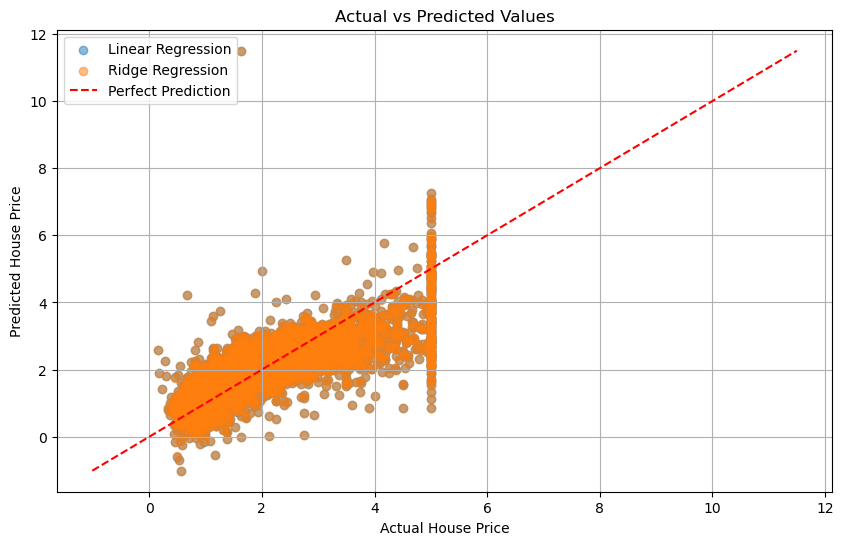

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.5, label="Linear Regression")
plt.scatter(y_test, ridge_pred, alpha=0.5, label="Ridge Regression")

minimum = min(y_test.min(), y_pred.min(), ridge_pred.min())
maximum = max(y_test.max(), y_pred.max(), ridge_pred.max())

plt.plot([minimum, maximum], [minimum, maximum],
         "r--", label="Perfect Prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()